<a href="https://colab.research.google.com/github/aderald0/deteccao-fraude-cartao-credito/blob/main/deteccao_fraude_cartao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q xgboost shap imbalanced-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    recall_score,
    precision_score,
    f1_score
)

from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import shap

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [2]:
URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(URL)

print(f"Formato do dataset: {df.shape}")
print(f"Valores nulos: {df.isnull().sum().sum()}\n")
display(df.head())

# Proporção das classes
proporcao = df["Class"].value_counts(normalize=True) * 100
contagem = df["Class"].value_counts()

resumo_classes = pd.DataFrame({
    "Quantidade": contagem,
    "Proporção (%)": proporcao.round(4)
})
resumo_classes.index = ["Normal (0)", "Fraude (1)"]
display(resumo_classes)

Formato do dataset: (284807, 31)
Valores nulos: 0



,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,Quantidade,Proporção (%)
Normal (0),284315,99.8273
Fraude (1),492,0.1727


In [3]:
df_prep = df.copy()

# Transformação logarítmica no valor da transação
df_prep["Log_Amount"] = np.log1p(df_prep["Amount"])

# Engenharia de atributos temporal: hora do dia (ciclo de 24h)
df_prep["Hour"] = (df_prep["Time"] / 3600) % 24

# Remoção das colunas originais substituídas
X = df_prep.drop(columns=["Class", "Amount", "Time"])
y = df_prep["Class"]

# Separação estratificada mantendo a proporção de 0,17% de fraudes
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape} | Fraudes no treino: {y_train.sum()} ({y_train.mean()*100:.3f}%)")
print(f"Teste:  {X_test.shape}  | Fraudes no teste:  {y_test.sum()} ({y_test.mean()*100:.3f}%)")

Treino: (227845, 30) | Fraudes no treino: 394 (0.173%)
Teste:  (56962, 30)  | Fraudes no teste:  98 (0.172%)


In [4]:
# Peso para balanceamento no XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

modelos = {
    "Regressão Logística (Baseline)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest (Balanced)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            class_weight="balanced",
            n_jobs=-1,
            random_state=42
        ))
    ]),
    "XGBoost (Balanced)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", XGBClassifier(
            n_estimators=150,
            max_depth=6,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            tree_method="hist",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

resultados = []
probabilidades = {}

for nome, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    probabilidades[nome] = y_proba

    resultados.append({
        "Modelo": nome,
        "Recall (Fraude)": recall_score(y_test, y_pred),
        "Precisão (Fraude)": precision_score(y_test, y_pred),
        "F1-Score (Fraude)": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "PR-AUC": average_precision_score(y_test, y_proba)
    })

    print(f"=== {nome} ===")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Fraude"], digits=4))

df_resultados = pd.DataFrame(resultados).sort_values(by="PR-AUC", ascending=False)
display(df_resultados.style.format({
    "Recall (Fraude)": "{:.4f}",
    "Precisão (Fraude)": "{:.4f}",
    "F1-Score (Fraude)": "{:.4f}",
    "ROC-AUC": "{:.4f}",
    "PR-AUC": "{:.4f}"
}))

=== Regressão Logística (Baseline) ===
              precision    recall  f1-score   support

      Normal     0.9994    0.9998    0.9996     56864
      Fraude     0.8205    0.6531    0.7273        98

    accuracy                         0.9992     56962
   macro avg     0.9100    0.8264    0.8634     56962
weighted avg     0.9991    0.9992    0.9991     56962

=== Random Forest (Balanced) ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9997    0.9997     56864
      Fraude     0.8229    0.8061    0.8144        98

    accuracy                         0.9994     56962
   macro avg     0.9113    0.9029    0.9071     56962
weighted avg     0.9994    0.9994    0.9994     56962

=== XGBoost (Balanced) ===
              precision    recall  f1-score   support

      Normal     0.9997    0.9998    0.9998     56864
      Fraude     0.8737    0.8469    0.8601        98

    accuracy                         0.9995     56962
   macro avg     0.9367    0.

,Modelo,Recall (Fraude),Precisão (Fraude),F1-Score (Fraude),ROC-AUC,PR-AUC
2,XGBoost (Balanced),0.8469,0.8737,0.8601,0.9746,0.8792
1,Random Forest (Balanced),0.8061,0.8229,0.8144,0.9758,0.8226
0,Regressão Logística (Baseline),0.6531,0.8205,0.7273,0.9606,0.7363


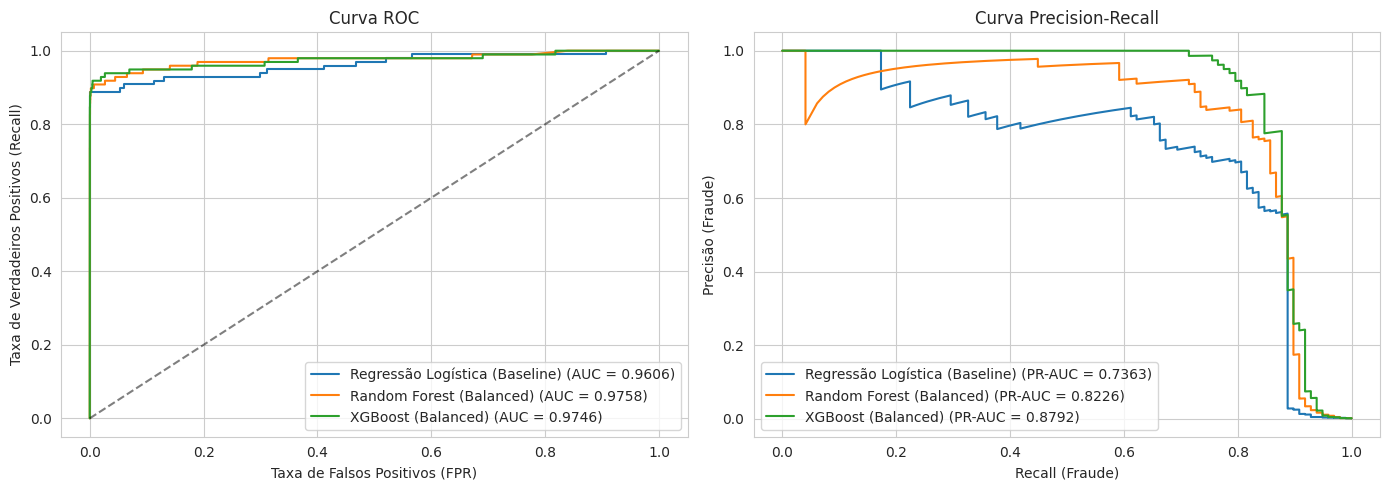

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva ROC
for nome, y_proba in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    axes[0].plot(fpr, tpr, label=f"{nome} (AUC = {auc_score:.4f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0].set_title("Curva ROC")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[0].legend()

# Curva Precision-Recall (principal métrica para dados desbalanceados)
for nome, y_proba in probabilidades.items():
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    ap_score = average_precision_score(y_test, y_proba)
    axes[1].plot(recall, precision, label=f"{nome} (PR-AUC = {ap_score:.4f})")

axes[1].set_title("Curva Precision-Recall")
axes[1].set_xlabel("Recall (Fraude)")
axes[1].set_ylabel("Precisão (Fraude)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [6]:
estrategias = {
    "XGBoost + Undersampling": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", RandomUnderSampler(random_state=42)),
        ("model", XGBClassifier(
            n_estimators=150, max_depth=6, learning_rate=0.1,
            tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=-1
        ))
    ]),
    "XGBoost + Oversampling (SMOTE)": ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", SMOTE(random_state=42)),
        ("model", XGBClassifier(
            n_estimators=150, max_depth=6, learning_rate=0.1,
            tree_method="hist", eval_metric="logloss", random_state=42, n_jobs=-1
        ))
    ])
}

comp_amostragem = []
for nome, pipe in estrategias.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    comp_amostragem.append({
        "Estratégia": nome,
        "Recall (Fraude)": recall_score(y_test, y_pred),
        "Precisão (Fraude)": precision_score(y_test, y_pred),
        "F1-Score (Fraude)": f1_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_proba)
    })

display(pd.DataFrame(comp_amostragem))

,Estratégia,Recall (Fraude),Precisão (Fraude),F1-Score (Fraude),PR-AUC
0,XGBoost + Undersampling,0.918367,0.034562,0.066617,0.685452
1,XGBoost + Oversampling (SMOTE),0.867347,0.548387,0.671937,0.861078


In [7]:
pipe_xgb = Pipeline([
    ("scaler", StandardScaler()),
    ("model", XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [4, 6],
    "model__learning_rate": [0.05, 0.1]
}

grid = GridSearchCV(
    estimator=pipe_xgb,
    param_grid=param_grid,
    scoring="recall",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)
best_pipe = grid.best_estimator_

print("Melhores hiperparâmetros:", grid.best_params_)
print(f"Melhor Recall na validação cruzada: {grid.best_score_:.4f}\n")

# Comparação de limiares de decisão no conjunto de teste
y_proba_best = best_pipe.predict_proba(X_test)[:, 1]

for limiar in [0.5, 0.3]:
    y_pred_limiar = (y_proba_best >= limiar).astype(int)
    print(f"--- Limiar de decisão: {limiar} ---")
    print(classification_report(y_test, y_pred_limiar, target_names=["Normal", "Fraude"], digits=4))
    cm = confusion_matrix(y_test, y_pred_limiar)
    print(f"Verdadeiros Negativos: {cm[0,0]} | Falsos Positivos: {cm[0,1]}")
    print(f"Falsos Negativos:      {cm[1,0]} | Verdadeiros Positivos: {cm[1,1]}\n")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Melhores hiperparâmetros: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 100}
Melhor Recall na validação cruzada: 0.8655

--- Limiar de decisão: 0.5 ---
              precision    recall  f1-score   support

      Normal     0.9998    0.9930    0.9964     56864
      Fraude     0.1786    0.8878    0.2974        98

    accuracy                         0.9928     56962
   macro avg     0.5892    0.9404    0.6469     56962
weighted avg     0.9984    0.9928    0.9952     56962

Verdadeiros Negativos: 56464 | Falsos Positivos: 400
Falsos Negativos:      11 | Verdadeiros Positivos: 87

--- Limiar de decisão: 0.3 ---
              precision    recall  f1-score   support

      Normal     0.9998    0.9795    0.9896     56864
      Fraude     0.0703    0.8980    0.1305        98

    accuracy                         0.9794     56962
   macro avg     0.5351    0.9388    0.5600     56962
weighted avg     0.

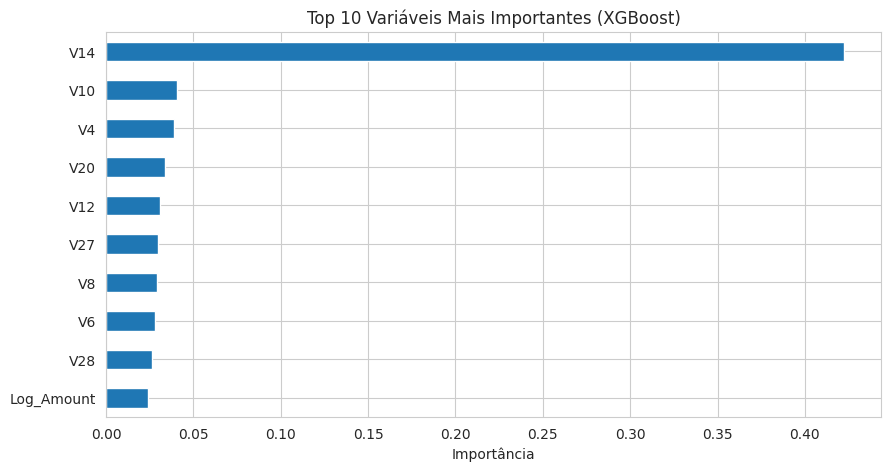

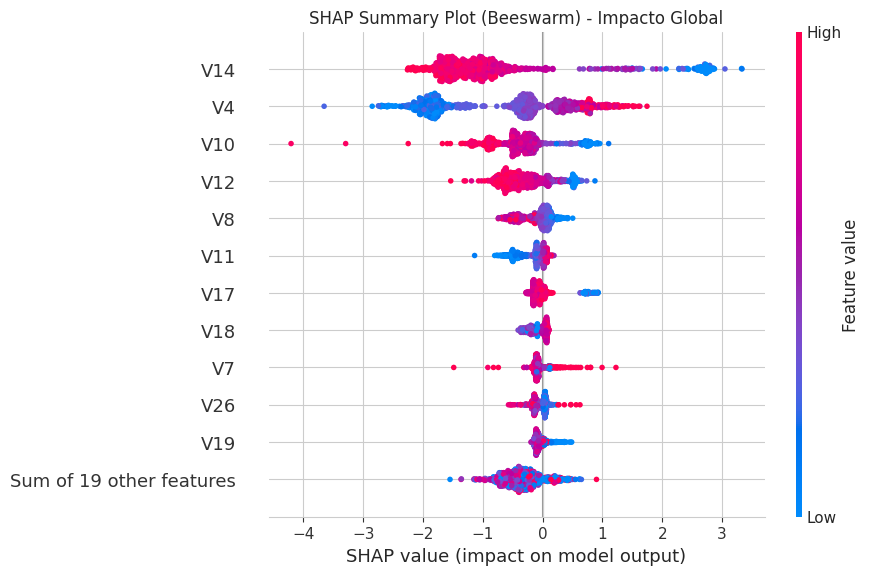

Explicação individual para a transação (índice 541 - Classe Real: Fraude):


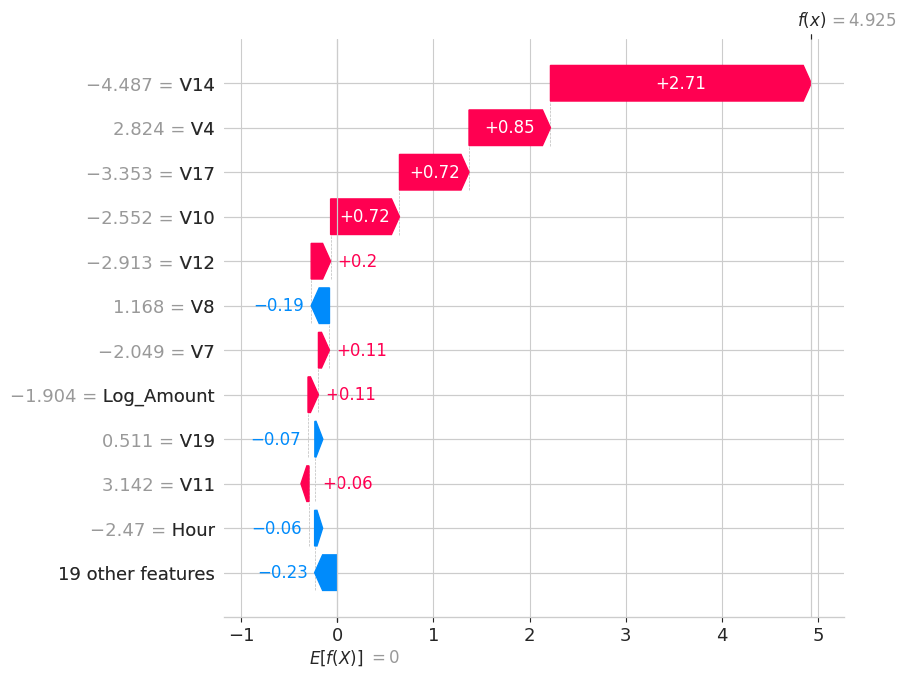

In [8]:
# 1. Importância nativa do modelo vencedor (XGBoost)
modelo_final = best_pipe.named_steps["model"]
scaler_final = best_pipe.named_steps["scaler"]

importances = pd.Series(modelo_final.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10).plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Top 10 Variáveis Mais Importantes (XGBoost)")
plt.xlabel("Importância")
plt.show()

# 2. Preparação da amostra para o SHAP
idx_fraudes = y_test[y_test == 1].index
idx_normais = y_test[y_test == 0].sample(n=1000, random_state=42).index
idx_amostra = idx_fraudes.union(idx_normais)

X_amostra = X_test.loc[idx_amostra]
X_amostra_scaled = pd.DataFrame(
    scaler_final.transform(X_amostra),
    columns=X.columns,
    index=X_amostra.index
)

# Cálculo dos valores SHAP
explainer = shap.TreeExplainer(modelo_final)
shap_values = explainer(X_amostra_scaled)

# Visão global: impacto de cada variável na predição de fraude
plt.title("SHAP Summary Plot (Beeswarm) - Impacto Global")
shap.plots.beeswarm(shap_values, max_display=12)

# Visão local: explicando uma transação fraudulenta específica
pos_fraude = np.where(y_test.loc[idx_amostra].values == 1)[0][0]
print(f"Explicação individual para a transação (índice {idx_amostra[pos_fraude]} - Classe Real: Fraude):")
shap.plots.waterfall(shap_values[pos_fraude], max_display=12)